# Agents, Session 4: Agent Architectures and Design Patterns

## The night the agent thought too hard

DilSeTrips now serves 2,000 couples. Last Saturday at 7:40 pm, one of them typed:

> "Help, our car broke down on the road to Rohtang and it's getting dark. What do we do?"

The agent did what it always does. It perceived the request, retrieved the couple's memories, checked the weather tool, searched the travel guide, and forty seconds later produced a beautifully formatted answer with nearby sights, the forecast and a vegetarian dinner suggestion. The emergency number was in paragraph four.

Nobody was hurt. But the post-mortem the next morning asked a question this course has not yet asked directly: **does every message deserve the same amount of thinking?** A request for a 5-day itinerary deserves planning and tools. "Help, we're stranded" deserves an instant, fixed, correct answer. And "the flight's been cancelled" deserves something in between: not a fresh plan from scratch, but a change to the plan already in progress.

That is what **agent architecture** is about. Last session was about what an agent remembers; this one is about how it thinks and acts. Today we cover five architectures, from classical AI to architectures built around LLMs, and four design patterns that every LLM agent uses. You will write GenAI code for each, and finish by rebuilding DilSeTrips so that Saturday night cannot happen again.

The question to hold on to throughout: **how much thinking does this moment need, and who decides?**

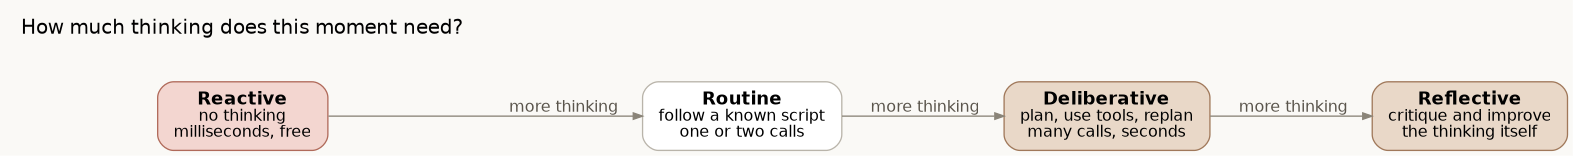

*Every architecture and pattern in this session is a way of choosing a point on this dial, or of switching between points.*

### Setup

About 40 Gemini calls in total. The rate limiter makes calls wait their turn on the free tier.

In [ ]:
%pip install -q "langchain>=1.0" "langchain-google-genai>=4.0" requests

In [ ]:
import os
import json
import time
import requests
from getpass import getpass
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_core.messages import HumanMessage, SystemMessage
from langchain.agents import create_agent

if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = getpass("Paste your Gemini API key: ")

# At most 4 calls a minute (the free tier allows 5), shared by everything in this notebook
rate_limiter = InMemoryRateLimiter(requests_per_second=4 / 60, check_every_n_seconds=0.5, max_bucket_size=1)
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", google_api_key=os.environ["GOOGLE_API_KEY"], rate_limiter=rate_limiter)

print(llm.invoke("In one sentence, welcome a class to a session on agent architectures.").text)

Two real tools from earlier sessions, used throughout: a weather forecast (Open-Meteo) and a travel guide (Wikivoyage). Neither needs an API key.

In [ ]:
def get_weather_forecast(place: str, region: str = "") -> str:
    """Get the daily weather forecast for the next 7 days (min and max temperature, rain, snow) for a town.

    Args:
        place: The town or city, for example Manali.
        region: Optional state or region to pick the right place, for example Himachal Pradesh.
    """
    found = requests.get("https://geocoding-api.open-meteo.com/v1/search", params={"name": place, "count": 10}, timeout=30).json()
    if "results" not in found:
        return f"Could not find a place called {place}."
    chosen = found["results"][0]
    for candidate in found["results"]:
        if region != "" and region.lower() in candidate.get("admin1", "").lower():
            chosen = candidate
            break
    daily = requests.get("https://api.open-meteo.com/v1/forecast", params={
        "latitude": chosen["latitude"], "longitude": chosen["longitude"], "timezone": "auto", "forecast_days": 7,
        "daily": "temperature_2m_min,temperature_2m_max,precipitation_sum,snowfall_sum"}, timeout=30).json()["daily"]
    lines = []
    for position in range(len(daily["time"])):
        lines.append(f"{daily['time'][position]}: {daily['temperature_2m_min'][position]} to {daily['temperature_2m_max'][position]} C, "
                     f"rain {daily['precipitation_sum'][position]} mm, snow {daily['snowfall_sum'][position]} cm")
    return f"Forecast for {chosen['name']}, {chosen.get('admin1', '')} (next 7 days only): " + "; ".join(lines)

def search_travel_guide(place: str) -> str:
    """Read the Wikivoyage travel guide for a place (its Understand, Get in, See, Do, Eat and Sleep sections).

    Args:
        place: The name of the place, for example Shimla.
    """
    response = requests.get("https://en.wikivoyage.org/w/api.php",
                            params={"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": place, "format": "json"},
                            headers={"User-Agent": "GenAI-course-agents-notebook/1.0 (educational use)"}, timeout=30)
    pages = response.json()["query"]["pages"]
    for page_id in pages:
        if "extract" in pages[page_id]:
            return pages[page_id]["extract"][:4000]
    return f"No Wikivoyage page found for {place}."

print(get_weather_forecast("Manali", "Himachal Pradesh")[:200])

## 1. Why architecture matters

Would you build a house by nailing boards together at random, or start with a blueprint? An **agent architecture** is that blueprint: the fundamental structure of an agent, how its components connect, and how information flows as it perceives, reasons and acts. It is the agent's internal operating system, and it separates a toy from a tool in three ways.

**Scalability: from a small town to a megacity.** A town built without a plan, with narrow roads and random pipes, works for a few hundred people; when thousands arrive you get gridlock and shortages. A planned grid grows into a metropolis. Amazon's early system was simple; to serve millions of users and transactions per second it moved to microservices, where authentication, search, cart and payment are separate services, so one can be fixed or scaled (payments on Black Friday) without taking down the site. A good agent architecture lets you add skills, data and users without redesigning everything.

**Efficiency: the professional chef's kitchen.** A master chef with everything in place (mise en place) cooks a complex dish with no wasted movement; a novice in a messy kitchen spends most of the time searching. Google Maps processes huge streams of real-time traffic and closures and returns a route in seconds because its architecture is built for exactly that; a poorly designed one would be uselessly slow. An efficient architecture makes good decisions quickly without wasting resources, which, for LLM agents, means not spending forty seconds of model calls on a message that needs none.

**Adaptability: Lego, not a glued model.** A glued model car does one thing perfectly and can never change. A Lego car can get bigger wheels or become a truck. A personalised news feed has to adapt as you read more about AI and less about celebrities; its modular design lets it update its picture of you. A modular architecture is easier for developers to change, and it is the foundation for an agent that can eventually learn and adapt by itself.

### Architecture versus design pattern

The two terms are easy to confuse.

**Architecture** is the high-level organisation of the whole system: the blueprint of the entire house. It defines the main components (foundation, rooms, roof), how they relate (where the plumbing runs, where the stairs go) and the overall principles (a single-storey ranch or a three-storey Victorian). For agents: a subsumption architecture, a BDI architecture, a layered architecture.

A **design pattern** is a proven, reusable solution to a recurring problem *within* an architecture: the kitchen work triangle, cross-ventilation window placement, the design of a roof truss. In software: the Singleton pattern, or the Observer pattern. For LLM agents: Planning, ReAct, Tool Use and Reflection.

In short: **architecture is the city plan; design patterns are the best designs for its intersections, parks and buildings.** We start with architectures.

## 2. Five agent architectures

Robots in rooms, assistants helping users, systems analysing data: all need a way to decide what to do in different situations. Classical AI designed agents with deliberative planning, reactive behaviours or hybrids, which worked well in structured, predictable, task-specific settings. LLMs widened what agents can do: understand language, reason over knowledge, keep long-term context and interact like people. Either way, an agent needs an architecture: a definition of **how it perceives, reasons and acts**.

Each architecture below appeared to fix a weakness of the one before.

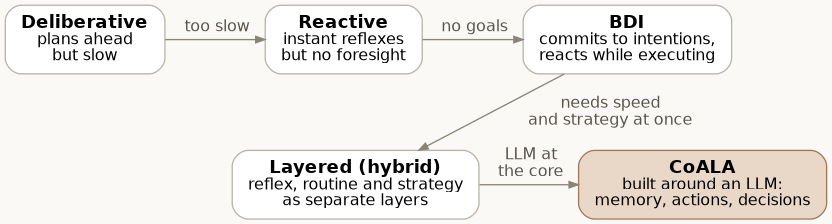

*Each architecture answers the main weakness of the previous one.*

### 2.1 Deliberative architecture: the chess grandmaster

A grandmaster does not play the first move that comes to mind. They observe the board, think several moves ahead, and then act. That is a **deliberative architecture**: **sense → think → act**. An LLM-based deliberative agent works the same way, with the LLM as the grandmaster's brain.

| Component | Chess grandmaster | LLM-based agent |
|---|---|---|
| World model | The mental image of the board: every piece, its value, the threats | The context and memory: prompt, conversation history, the reasoning scratchpad |
| Goal | Checkmate | Fulfil the user's request ("write a report on climate change") |
| Actions | The legal moves ("knight to F3") | The available tools and APIs (`search_web`, `write_file`, `execute_code`) |
| Planner | Evaluating sequences of moves to find the strongest line | The LLM, writing a step-by-step plan before acting |

**The world model** comes from three sources: the **prompt** (the initial board setup: system prompt plus user query), the **scratchpad** (chain-of-thought reasoning that evolves as the agent thinks: "the user wants a flight; I'm missing the destination and dates, so I'll ask"), and **external memory** (a vector database of past interactions, like a grandmaster recalling famous games).

**Goals** are broken down: "write a market analysis for product X" becomes research the market and competitors (the opening), analyse trends (the middlegame), and synthesise a report (the endgame).

**Actions** are limited to the tools provided, as chess moves are limited by the rules. Each tool has **preconditions** (what must be true first) and **effects** (what changes): before `write_file`, you need content; afterwards, the file exists.

**The planner** is the LLM itself. It does not run a formal search algorithm; it uses pattern recognition and reasoning to simulate a strategy, expressed as a loop of thoughts and actions. Asked "our market share is falling; why, and what should we do?", it thinks "I need data first", calls `search_web`, observes competitor pricing, thinks "now analyse the causes", and so on.

**Strengths:** flexible and general (it handles unstructured problems no classical planner could); human-like, explainable reasoning; better at recovering from surprises (a failed tool call can be reflected on and replanned). **Weaknesses:** **hallucination** (a plan built on a flawed world model); **cost and latency** (the classical "analysis paralysis" becomes a cost problem); the **black box** (you see *what* it thought, not *why*); and a new form of the **frame problem** (the world model goes out of date as soon as the world changes).

One useful practice follows directly from the preconditions and effects: **let the LLM propose the plan, and let code check it.** Below, DilSeTrips has six actions with written-down preconditions. Gemini plans a hotel booking; plain Python checks that every step's preconditions are met by earlier steps.

**Before you run it:** will Gemini remember that booking needs the couple's approval first?

In [ ]:
action_rules = {
    "ask_user":        {"needs": [],                                "gives": ["dates", "user approval"]},
    "check_weather":   {"needs": ["destination"],                   "gives": ["weather"]},
    "search_hotels":   {"needs": ["destination", "dates"],          "gives": ["hotel options"]},
    "book_hotel":      {"needs": ["hotel options", "user approval"], "gives": ["booking"]},
    "write_itinerary": {"needs": ["weather", "hotel options"],      "gives": ["itinerary"]},
    "send_summary":    {"needs": ["itinerary"],                     "gives": ["summary sent"]},
}
action_names = []
action_descriptions = ""
for name in action_rules:
    action_names.append(name)
    action_descriptions = action_descriptions + f"- {name}: needs {action_rules[name]['needs']}, gives {action_rules[name]['gives']}\n"

plan_schema = {"title": "plan", "description": "An ordered plan", "type": "object",
               "properties": {"steps": {"type": "array", "items": {"type": "object", "properties": {
                   "action": {"type": "string", "enum": action_names}, "why": {"type": "string"}},
                   "required": ["action", "why"]}}},
               "required": ["steps"]}

goal = "Book a hotel in Manali for our trip and send us an itinerary."
known_at_start = ["destination"]
plan = llm.with_structured_output(plan_schema).invoke(
    f"Goal: {goal}\nYou already know: {known_at_start}\nAvailable actions:\n{action_descriptions}"
    "Write the shortest plan that reaches the goal. Do not carry anything out.")

# Code checks the LLM's plan against the preconditions
known = list(known_at_start)
plan_is_valid = True
for number in range(len(plan["steps"])):
    step = plan["steps"][number]
    missing = []
    for requirement in action_rules[step["action"]]["needs"]:
        if requirement not in known:
            missing.append(requirement)
    if len(missing) > 0:
        plan_is_valid = False
        print(f"Step {number + 1}: {step['action']:15s} INVALID - missing {missing}")
    else:
        print(f"Step {number + 1}: {step['action']:15s} ok   ({step['why']})")
    for effect in action_rules[step["action"]]["gives"]:
        known.append(effect)

print("\nPlan valid:", plan_is_valid)

Gemini usually produces a valid plan here, often starting with `ask_user` because it can see `book_hotel` needs approval. But when it skips a step (say, booking before asking), the code catches it every time, before anything runs. This is the combination CoALA will recommend later: **the LLM for flexible ideas, code for strict rules.**

Deliberative agents are powerful but slow and expensive. What about moments where thinking at all is the wrong move?

### 2.2 Reactive architecture: the hand on the hot stove

Touch a hot stove and you do not consider the chemistry of heat or plan a response. You pull your hand away *instantly*. A **reactive architecture** gives an agent that reflex. Its motto: **sense → act**, with no planning or modelling in between.

Think of a cockroach. It senses a shadow and scurries; it senses a wall with its antennae and turns. It has no map of the kitchen and no goal of crossing it; it reacts with pre-programmed survival behaviours. A reactive agent breaks a task into simple, independent rules of the form `IF <sensor condition> THEN <action>`: `IF bumper_sensor == PRESSED THEN reverse_and_turn()`; `IF light_sensor > 70% THEN move_forward()`; `IF battery_level < 10% THEN find_charger()`. Intelligent behaviour **emerges** from many rules running together.

**The subsumption architecture**, developed by Rodney Brooks at MIT in the 1980s as a rebellion against slow symbolic AI, organises these behaviours into a **hierarchy of layers**. For a robot vacuum: Layer 0, **avoid obstacles**, has the highest priority (if you are about to hit something, override everything and turn); Layer 1, **wander** (if nothing else is happening, move forward); Layer 2, **clean** (if moving, switch on suction). Higher-priority layers can **suppress, or subsume**, the output of lower ones. When the bumper fires, Layer 0 shouts "stop!", takes the wheels, turns, and goes quiet again. And if the cleaning layer fails, the robot still wanders and avoids walls.

**Strengths:** extremely fast; robust (one failing behaviour does not crash the rest); computationally cheap; surprisingly capable behaviour from simple rules. **Weaknesses:** no long-term planning (the vacuum cannot plan an efficient route); no world model (it cleans the same spot again and again); hard to scale (predicting how hundreds of rules interact is difficult).

This is exactly what DilSeTrips lacked on Saturday night: a reflex layer in front of the thinking.

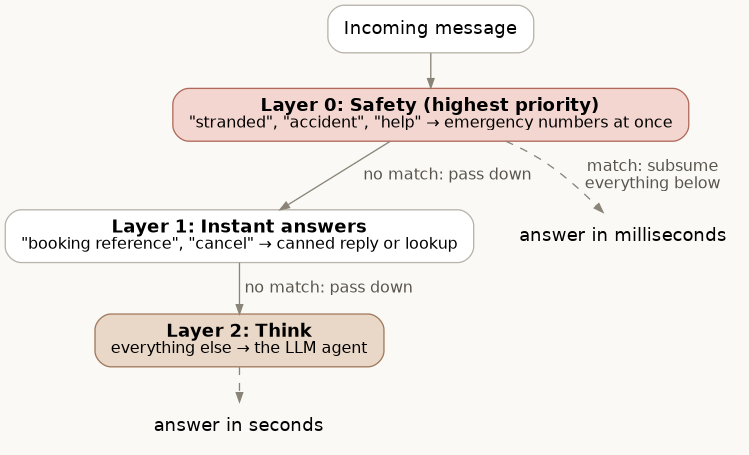

*Higher layers answer first and subsume everything below; only unmatched messages reach the LLM.*

In [ ]:
emergency_words = ["stranded", "broke down", "broken down", "accident", "help us", "emergency", "we're lost", "injured"]
instant_answers = {
    "booking reference": "Your booking reference is in the confirmation email and under My Trips > Bookings.",
    "cancel my booking": "You can cancel free of charge up to 48 hours before check-in under My Trips > Bookings > Cancel.",
}
emergency_reply = ("EMERGENCY: Call 112 now (India's national emergency number for police, fire and ambulance). "
                   "Stay with your vehicle if it is safe, switch on hazard lights, and share your live location with family. "
                   "We are alerting the DilSeTrips support team to call you.")

def reactive_layer(message):
    """Layer 0 and Layer 1: fixed rules, no LLM. Returns a reply, or None to pass the message down."""
    lowered = message.lower()
    # TODO: HW1 [Easy] - Keyword reflexes are fast but brittle. Find a real emergency this misses and a harmless message it
    # wrongly flags (try the ones in the next cell first). Would you rather miss an emergency or raise a false alarm? Why?
    for word in emergency_words:
        if word in lowered:
            return emergency_reply
    for phrase in instant_answers:
        if phrase in lowered:
            return instant_answers[phrase]
    return None

saturday_message = "Help, our car broke down on the road to Rohtang and it's getting dark. What do we do?"

start = time.perf_counter()
reflex_reply = reactive_layer(saturday_message)
reflex_seconds = time.perf_counter() - start

start = time.perf_counter()
thinking_reply = llm.invoke(saturday_message)
thinking_seconds = time.perf_counter() - start

print(f"Reactive layer ({reflex_seconds * 1000:.3f} ms):\n{reflex_reply}\n")
print(f"LLM ({thinking_seconds:.1f} s, including any wait for the rate limiter):\n{thinking_reply.text[:500]}")

The reflex answers in a fraction of a millisecond with a fixed, reviewed, correct reply. The LLM takes seconds (more on a busy free tier) and its answer, though usually sensible, is not guaranteed to put 112 first. For a safety-critical moment, the fast, predictable path wins.

But look at what reflexes cannot do.

In [ ]:
tricky_messages = [
    "Our car died near Rohtang pass and there's no signal, what now?",     # a real emergency, no keyword
    "I'm lost for words, this trip was amazing!",                          # harmless
    "Can you help us find a quiet cafe in Old Manali?",                    # harmless
]
for message in tricky_messages:
    reply = reactive_layer(message)
    if reply is None:
        print(f"PASSED DOWN   {message}")
    else:
        print(f"REFLEX FIRED  {message}\n              -> {reply[:60]}...")

"Our car died" is a real emergency, but it matches no keyword, so it is passed down to the slow path. "Help us find a cafe" contains "help us", so it triggers a false alarm. Reflexes are fast precisely *because* they do not understand. That trade-off is why real systems combine reflexes with thinking, which is where the next architectures go.

### When to use which

| Aspect | Deliberative | Reactive |
|---|---|---|
| Speed | Slower: plans and reasons | Very fast: direct stimulus to action |
| Best for | Complex tasks needing foresight and strategy | Dynamic, uncertain environments needing quick responses |
| Example | Planning a delivery route around traffic | An autonomous car braking for a sudden pedestrian |
| Strength | Deep reasoning, long-term goals | Robust in real time |
| Weakness | Expensive; "paralysis by analysis" | No foresight; cannot handle abstract or long-term goals |
| Analogy | A grandmaster planning ten moves ahead | Pulling your hand away from a flame |

This tension, thinking too much versus not thinking enough, led researchers to a middle ground.

### 2.3 BDI: Belief, Desire, Intention

The BDI architecture gives the agent a structured "mind" that guides its actions without a full, fresh plan for every step. It rests on three mental attitudes.

**Beliefs (informational state)** are the agent's model of the world and of itself. They are "beliefs", not "facts", because they can be incomplete or wrong, and they are updated by sensing and reasoning. A rescue robot might believe `at(robot, room_A)`, `obstacle(blocked_door)`, `victim_location(room_C)`. In Session 3's terms, beliefs live in the agent's **semantic memory** (facts: "the couple is vegetarian") and **episodic memory** (experiences: "the taxi ride last time was awful").

**Desires (motivational state)** are everything the agent would like to achieve, and they can conflict: `rescue_victim`, `recharge_battery`, `avoid_damage`.

**Intentions (deliberative state)** are the desires the agent has **committed** to, each with a plan: intention `rescue_victim`, plan `[go_to(room_C), carry(victim), go_to(safe_zone)]`. Commitment is the key idea. Once an agent forms an intention, it does not get sidetracked by every new piece of information.

BDI blends the two earlier architectures in a continuous cycle. **Deliberation** (desire to intention) is the planner: periodically the agent steps back, reviews its beliefs and desires, decides which desire matters most, and picks a plan from its plan library. **Execution** is reactive: it carries out the plan step by step and handles local surprises without scrapping everything. A sudden obstacle triggers `move_around_obstacle`, not a whole new plan. Only a major change makes it reconsider the intention itself. So it is neither paralysed by planning nor aimlessly reactive.

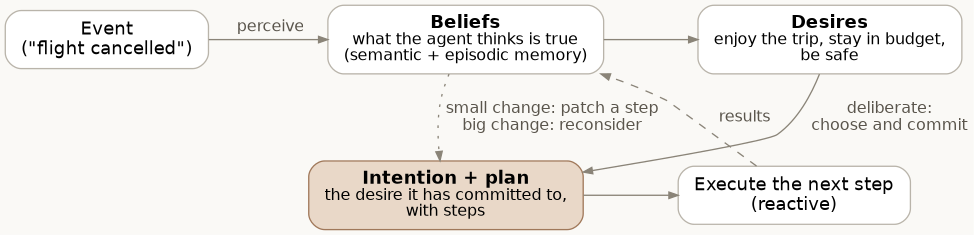

*Beliefs and desires feed a committed intention. Small changes patch a step; big changes trigger reconsideration.*

**BDI with an LLM.** Classical BDI agents relied on hand-written rules and a fixed plan library: a travel-planning BDI robot could book hotels only if a rule for it existed. An LLM can form beliefs, infer desires and generate intentions on the fly. **Beliefs** come from pre-trained knowledge, the current conversation, real-time tool results and stored memories. **Desires** come from the system prompt and the user's request, plus sub-desires the LLM infers ("plan a trip to Paris" implies flights, a hotel and attractions). **Intentions** are plans generated dynamically and carried out in a think-act-observe (ReAct) loop.

| Feature | Classical BDI agent | LLM-based agent |
|---|---|---|
| Knowledge | Explicit symbolic rules and facts | Model weights, current context, real-time data |
| Reasoning | Rule-based deduction, formal planning | Natural-language reasoning, dynamic plans |
| Planning | A predefined plan library | Plans generated on the fly |
| Flexibility | Limited to programmed rules | Generalises to tasks it was not built for |

Back to Saturday's second problem: the old DilSeTrips re-planned the whole trip whenever anything changed. Here is a BDI companion for Prasad's Manali trip. Gemini forms the beliefs, desires and intention once; then two events arrive, one small and one big.

**Before you run it:** which event should change the intention, and which should only patch a step?

In [ ]:
bdi_schema = {
    "title": "bdi_state", "description": "An agent's beliefs, desires and committed intention", "type": "object",
    "properties": {
        "beliefs": {"type": "array", "items": {"type": "string"}},
        "desires": {"type": "array", "items": {"type": "string"}},
        "intention": {"type": "string", "description": "The one desire the agent commits to now"},
        "plan": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["beliefs", "desires", "intention", "plan"],
}
trip_context = ("Prasad and his partner fly Delhi to Kullu on 6E 2073 at 11:05 on 20 December, then stay 3 nights at "
                "Snow Valley Cottage, Old Manali (check-in 1 pm). She is vegetarian; he gets sick on long road trips. "
                "Budget is tight. They want a quiet, relaxing trip, and Solang Valley on day 2.")

bdi = llm.with_structured_output(bdi_schema).invoke("Form beliefs, desires, one committed intention and a short plan "
                                                     "for a travel companion agent supporting this trip:\n" + trip_context)
print("Intention:", bdi["intention"])
for step in bdi["plan"]:
    print("  -", step)

In [ ]:
reconsider_schema = {
    "title": "reconsideration", "description": "How an event affects the current intention", "type": "object",
    "properties": {
        "change_size": {"type": "string", "enum": ["small: patch a step", "big: reconsider the intention"]},
        "reason": {"type": "string"},
        "intention": {"type": "string"},
        "plan": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["change_size", "reason", "intention", "plan"],
}
reconsider_llm = llm.with_structured_output(reconsider_schema)
# TODO: HW6 [Hard] - Here every belief is passed in every call. Store them in a Session 3 style vector memory (semantic beliefs
# for facts, episodic for experiences) and retrieve only the relevant ones. What changes with a hundred beliefs instead of six?

events = [
    "Snow Valley Cottage says check-in will be at 3 pm instead of 1 pm.",
    "IndiGo has cancelled 6E 2073: a snowstorm will close Kullu airport for two days.",
]
for event in events:
    result = reconsider_llm.invoke(
        f"Current beliefs: {bdi['beliefs']}\nDesires: {bdi['desires']}\nCommitted intention: {bdi['intention']}\n"
        f"Plan: {bdi['plan']}\n\nNew event: {event}\n"
        "A BDI agent stays committed to its intention unless an event makes it impossible or clearly wrong. "
        "Decide whether this is a small change (patch one step) or a big one (reconsider the intention), and return the result.")
    print(f"EVENT: {event}\n  -> {result['change_size']}: {result['reason']}")
    print(f"  intention: {result['intention']}")
    print(f"  plan: {result['plan']}\n")

The late check-in should be a small change: the intention (a relaxing trip) and almost all the plan survive; one step moves. The cancelled flight should be big: the intention itself is reconsidered (perhaps "get there safely a day later" or "rebook and shorten the trip"). That is commitment with reconsideration, the heart of BDI, and it is far cheaper and calmer than re-planning everything on every message.

BDI has limits. It assumes beliefs, desires and intentions can be cleanly separated, which blurs in messy real situations. And it struggles when an environment needs **fast reflexes and long-term strategy at the same time**: a support agent may pursue a long-term goal (resolve the issue) while also needing to flag harmful content instantly or answer a simple FAQ without heavy reasoning. That gap led to layered architectures.

### 2.4 Layered (hybrid) architectures

A layered architecture structures the agent's control into **distinct layers**, each responsible for a different level of abstraction, so that it can react instantly to threats *and* pursue long-term goals. It answers the weaknesses of both pure types: reactive agents are fast but aimless; deliberative agents are purposeful but slow.

A common design has three layers. In a self-driving car:

- **The reactive layer (instinct)** is the lowest and fastest, wired straight to sensors and actuators: brake instantly if an object appears. No reasoning about what the object is.
- **The sequencer or behavioural layer (habit)** manages routines: a lane change means check mirrors, signal, turn smoothly. It receives "change lanes" from above and handles the tactics itself, using pre-compiled routines rather than deep planning.
- **The deliberative layer (grandmaster)** is the highest and slowest: it plans the whole route around traffic and fuel stops, keeps a world model, and passes sub-goals down.

This design is common wherever speed and intelligence are both critical: robotics, autonomous vehicles, industrial automation.

**In an LLM agent, the layers are modes of operation**, chosen by an **orchestration engine**: the code wrapped around the LLM, which manages state, selects tools and decides how much thinking a moment gets.

- **Reactive mode:** an immediate response with no reasoning or tools, often no LLM at all: "I've received your request and will forward it to a human agent", triggered by a keyword.
- **Sequencer mode:** the LLM follows a known routine: to find a restaurant, get the location, then search with it. Structured but not complex.
- **Deliberative mode:** full reasoning: "plan a summer vacation" is decomposed into destination and dates, flights, hotels and activities, then synthesised, possibly delegating to other agents.

Control flows in two directions. **Bottom-up activation:** an urgent observation (an error, an emergency) bypasses the higher layers and gets an immediate reactive response, so the agent never gets stuck planning while something is on fire. **Top-down delegation:** the deliberative layer sets the goal and hands steps down for execution.

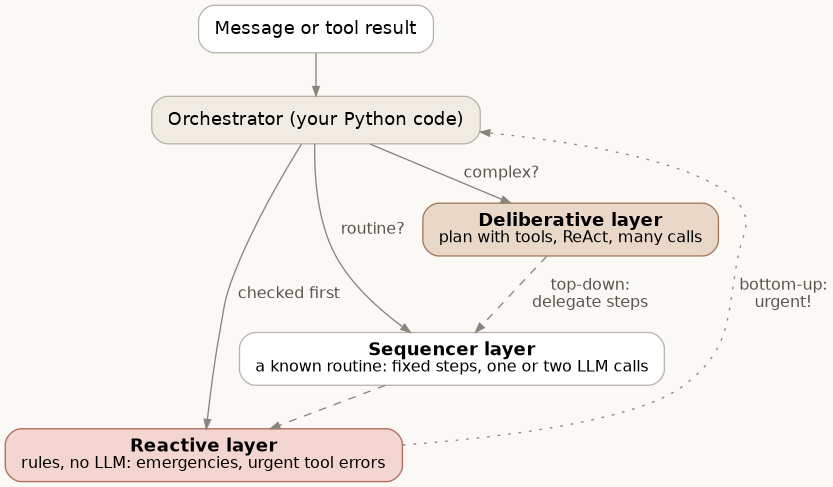

*Your Python orchestrator checks the reactive layer first, then sends each message to a routine or to full planning.*

Here is that orchestrator for DilSeTrips. The reactive layer is the one from 2.2. A small LLM router decides whether a message is a known **routine** (a packing list: always the same steps) or needs **deliberation** (anything open-ended). The routine is a fixed script: our code calls the weather tool itself, then one LLM call writes the list. The deliberative path is a full agent with tools.

In [ ]:
# TODO: HW2 [Medium] - "Our car died near Rohtang" slips past the keyword layer. Add an is_emergency field here and send
# emergencies to the reactive reply. What does that cost every message in latency, and could you call it only when needed?
router_schema = {"title": "route", "description": "Which layer should handle a message", "type": "object",
                 "properties": {"layer": {"type": "string", "enum": ["routine: packing list", "deliberative: needs planning"]},
                                "destination": {"type": "string", "description": "The place mentioned, or an empty string"}},
                 "required": ["layer", "destination"]}
router_llm = llm.with_structured_output(router_schema)

def packing_list_routine(message, destination):
    """Sequencer layer: a fixed script. Our code decides the steps; the LLM only fills one in."""
    forecast = get_weather_forecast(destination)                                      # step 1, always
    reply = llm.invoke(f"Request: {message}\nForecast: {forecast}\n"
                       "Write a packing list of at most 8 items based on this forecast.")  # step 2, always
    return reply.text

planning_agent = create_agent(model=llm, tools=[get_weather_forecast, search_travel_guide],
                              system_prompt="You are DilSeTrips. Plan with your tools, then answer in under 150 words.")

def orchestrator(message):
    reflex = reactive_layer(message)                       # bottom layer, checked first, no LLM
    if reflex is not None:
        return "reactive", reflex
    route = router_llm.invoke("Route this message to a DilSeTrips layer:\n" + message)
    if route["layer"].startswith("routine") and route["destination"] != "":
        return "sequencer", packing_list_routine(message, route["destination"])
    result = planning_agent.invoke({"messages": [HumanMessage(content=message)]})
    return "deliberative", result["messages"][-1].text

test_messages = [
    saturday_message,
    "What should we pack for Manali this week?",
    "Plan a relaxed 2-day food trail in Amritsar for a vegetarian couple.",
]
for message in test_messages:
    start = time.perf_counter()
    layer, reply = orchestrator(message)
    print(f"[{layer}, {time.perf_counter() - start:.1f} s] {message}\n{reply[:400]}\n" + "-" * 70)

Three messages, three layers, three very different costs: the emergency is answered instantly with no LLM call; the packing list takes one router call and one writing call along a fixed path; the food trail gets full planning with tools. Saturday night now goes to the reactive layer.

Notice what this orchestrator does *not* fix: "our car died near Rohtang" still misses the keyword list. A better design adds a cheap LLM safety check as part of the router (homework 2). Layers make it easy to add exactly that, without touching the rest.

The layered approach treats the LLM as an engine bolted into an older frame. But you cannot just bolt a jet engine onto a horse-drawn carriage; the old blueprint was not designed for the new power. **CoALA** asks: if a powerful LLM sits at the very heart of an agent, how should we build the memory, actions and decision-making around it?

### 2.5 CoALA: Cognitive Architectures for Language Agents

CoALA is a framework, inspired by cognitive science, for organising existing language agents and designing new ones. It places the **LLM at the core of a larger cognitive architecture**. Think of it not as software but as an architect's blueprint for an AI's mind.

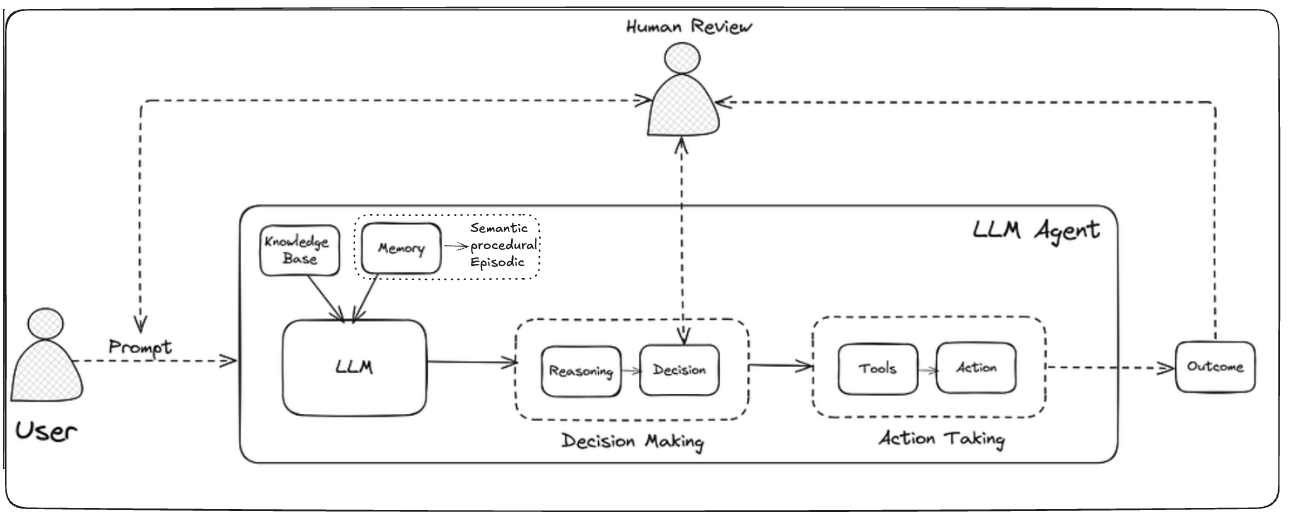

*A user's prompt flows through the LLM, reasoning and decision-making, to tools and an outcome, with knowledge, memory and human review around it.*

A query flows through three stages, usually in a loop. **Think:** the user's prompt reaches the LLM, which consults the **knowledge base** (static information: training data, manuals, uploaded documents) and **memory** (past interactions, preferences, what worked), then reasons step by step toward a plan. **Decide and act:** the agent makes a concrete decision, "what is the single best next step?", and carries it out, often with a tool (a calculator, a search API, a database). **Observe and review:** the outcome can go to a **human for review**, who corrects or approves it, and the final outcome is written back into memory, so the agent improves.

The session document's example: a customer writes to ShopFast.com, "I never received the sneakers I ordered last week! Order #12345." **Think:** the agent checks shipping policy and memory, and reasons "the customer is upset; first find the order status". **Act:** it calls `query_database(order_number=12345)` and learns the parcel shipped, tracking QP789XYZ, last updated three days ago. **Observe:** either it continues alone (checks the carrier, finds the new delivery date, replies, stores the interaction), or a human reviews the proposed reply ("delayed; here's a 10% coupon"), decides the delay is serious, raises it to 15% with a warmer apology, and that corrected interaction is stored so future replies are more generous.

CoALA rests on three pillars: **memory**, **actions** and **decisions**.

#### Memory: four modules

Session 3 covered these in depth, so briefly. **Working memory** is the agent's conscious mind: current inputs, goals and recently retrieved memories, constantly updated. **Episodic memory** is the diary of past experiences. **Semantic memory** is the encyclopedia of knowledge, pre-loaded and self-learned. **Procedural memory** is how-to knowledge, held both implicitly in the LLM's weights and explicitly in code and tools.

When an observation arrives, what happens first? It is **parsed** first, before any decision. Retrieval from the long-term memories then happens **in parallel**:

```
                ↗ Retrieval → Semantic memory
Observation → PARSE → Retrieval → Episodic memory
                ↘ Retrieval → Procedural memory
```

The retrieved information feeds reasoning in working memory, and only after reasoning does the decision procedure act. Each long-term store also has its own **learning** path: semantic memory learns new facts ("customers prefer email updates to SMS"), episodic memory learns new experiences ("customer #12345 was happy with expedited shipping"), and procedural memory learns better workflows ("check inventory before promising delivery dates").

#### Actions: internal and external

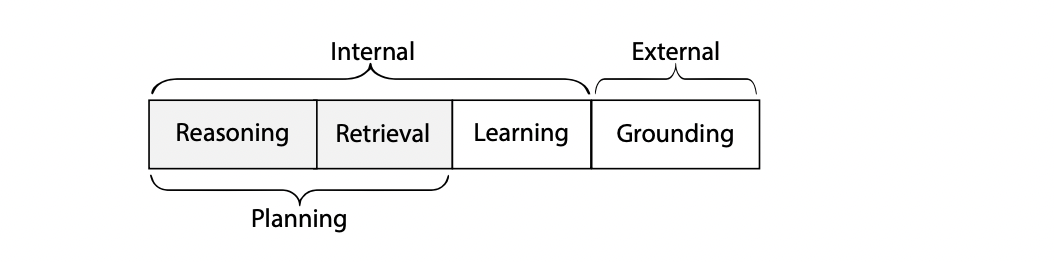

*Internal actions (reasoning, retrieval, learning) work on the agent's own memory; external actions (grounding) touch the world.*

**External actions** connect the agent to the world, which CoALA calls **grounding**: controlling a robot in a **physical environment**, talking with people in **dialogue**, or using tools such as APIs, websites and code in **digital environments** (the most common today). **Internal actions** work on the agent's own mind: **retrieval** reads from long-term memory into working memory ("recalling a memory"); **reasoning** processes working memory to produce new insight ("thinking"); **learning** writes to long-term memory ("saving a new memory", whether an experience, a fact, or even a new skill). Reasoning and retrieval together make up planning.

#### Decisions: propose, evaluate, select

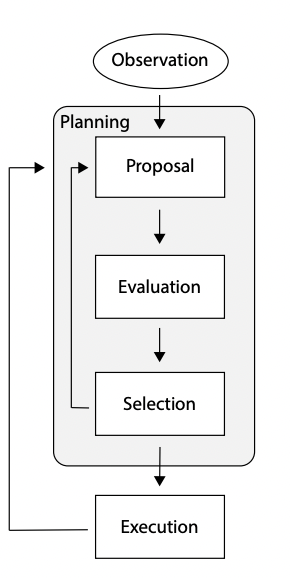

*Planning proposes, evaluates and selects an action; execution carries it out; the next observation starts the cycle again.*

How does the agent choose? It runs a **propose, evaluate, select** cycle, like a chess player. **Propose:** "I could move my knight here, or advance my pawn." **Evaluate:** "the knight threatens his queen: good; the pawn weakens my defence: bad", possibly simulating outcomes internally. **Select:** "the knight it is." Then execute, and repeat.

Two things are easy to mix up. The **reasoning loop inside working memory** is local *thinking*: mentally simulating options for the current task ("what could I do?"). The **overall decision process** is global *doing*: taking the result of that reasoning, choosing, and executing an action in the world ("what I will actually do").

Here is propose, evaluate, select for DilSeTrips. Gemini proposes candidate actions and labels each with its CoALA action type, a second call evaluates them, and plain Python selects.

In [ ]:
situation = ("The couple is in Old Manali. Tomorrow was planned as Solang Valley, but the forecast shows heavy snow "
             "and road closures. They are vegetarian and on a tight budget.")

propose_schema = {"title": "proposals", "description": "Candidate next actions", "type": "object",
                  "properties": {"candidates": {"type": "array", "items": {"type": "object", "properties": {
                      "action": {"type": "string"},
                      "action_type": {"type": "string", "enum": ["external: grounding", "internal: retrieval",
                                                                  "internal: reasoning", "internal: learning"]}},
                      "required": ["action", "action_type"]}}},
                  "required": ["candidates"]}
evaluate_schema = {"title": "evaluations", "description": "Scores for each candidate action", "type": "object",
                   "properties": {"scores": {"type": "array", "items": {"type": "object", "properties": {
                       "action": {"type": "string"}, "safety": {"type": "integer"}, "usefulness": {"type": "integer"},
                       "cost": {"type": "integer", "description": "10 = cheapest"}},
                       "required": ["action", "safety", "usefulness", "cost"]}}},
                   "required": ["scores"]}

# Propose
proposals = llm.with_structured_output(propose_schema).invoke(
    "Propose 3 different candidate next actions for a travel agent in this situation:\n" + situation)["candidates"]
for candidate in proposals:
    print(f"PROPOSED [{candidate['action_type']}] {candidate['action']}")

# Evaluate
candidate_text = ""
for candidate in proposals:
    candidate_text = candidate_text + "- " + candidate["action"] + "\n"
scores = llm.with_structured_output(evaluate_schema).invoke(
    f"Situation: {situation}\nScore each candidate from 1 to 10 for safety, usefulness and cost. "
    f"Copy each action exactly.\n{candidate_text}")["scores"]

# Select: plain arithmetic, visible
best_action = ""
best_total = -1
print()
for item in scores:
    total = 0.5 * item["safety"] + 0.3 * item["usefulness"] + 0.2 * item["cost"]
    print(f"EVALUATED 0.5x{item['safety']} + 0.3x{item['usefulness']} + 0.2x{item['cost']} = {total:.1f}  {item['action']}")
    if total > best_total:
        best_total = total
        best_action = item["action"]
print(f"\nSELECTED: {best_action}")

Notice the proposals often mix action types: an external one ("check the latest road status with the weather tool"), an internal retrieval ("recall which indoor places they enjoyed last time") and a reasoning step ("re-plan tomorrow as an indoor day"). And the selection weights safety most, because we chose to. Like the utility agent in Session 2, the LLM judges, and visible code decides.

CoALA encourages three habits: **build with Lego** (modular memory and action components you can swap); **combine brains and brawn** (code for structured, logical work such as checking a plan's preconditions, the LLM for flexible, creative work); and **create true learners** (agents that write to their own memories and improve over time). These are the habits this course has been practising since Session 1.

### 2.6 How the architectures relate, and when to choose each

They did not appear randomly. Each **evolved to fix the limits of the last**. **Deliberative (logic-based)** was the first attempt at thinking machines: strong at planning, weak at real-time adaptation. **Reactive** fixed responsiveness but lacks foresight. **BDI** brought structured mental states, balanced but rigid when the environment is very unpredictable. **Layered** added explicit coordination between reflex, routine and strategy. **CoALA** is the modern extension for LLMs, with memory, reasoning, tools and language built in. Think of a ladder: each step closes a practical gap.

| Architecture | Best for | Complexity | Performance | Adaptability |
|---|---|---|---|---|
| Deliberative (symbolic or logic) | Structured environments with clear rules (chess, scheduling) | High: explicit states, rules and planning | Low to medium: heavy reasoning | Low: struggles when things change |
| Reactive | Real-time, safety-critical, fast responses (obstacle avoidance) | Low: simple rules | High: very fast | Low: cannot adopt new goals; brittle |
| BDI | Goal-driven yet flexible behaviour (rescue robots, multi-task assistants) | Medium to high: mental states and plan libraries | Medium | Medium: bounded by its plans |
| Layered (hybrid) | Needs both reflexes and strategy (self-driving cars, customer support) | High: several layers to coordinate | High: fast reactions plus planning | High |
| CoALA (LLM agents) | Open-ended tasks needing reasoning, memory and tools (research assistants) | Variable: managed by the LLM and memory | Medium to high: depends on LLM speed | Very high |

There is no single best architecture. DilSeTrips, after Saturday, is a **layered** system whose deliberative layer is **CoALA-shaped** (LLM at the centre, memory and tools around it) and whose trip companion behaves like **BDI** (committed intentions). Real systems mix them.

Once you have an architecture, how do you build its parts so they are reusable and reliable? That is the job of design patterns.

## 3. Design patterns: proven ways to build the parts

A **design pattern** is a well-tested, reusable solution to a problem that keeps recurring inside an architecture. Architectures give the big picture of how an agent is structured; they do not answer the practical questions that come up in every project. Building a support agent, even with a hybrid architecture chosen, you still face: should it **plan steps** before replying, or answer at once? When should it **call an API** rather than generate the answer itself? How can it **avoid hallucinations** while staying flexible? Patterns answer these, and they **cut across** architectures.

For LLM agents, patterns matter even more, because LLMs are powerful but unpredictable. Patterns bring **structure** (less randomness and fewer hallucinations), **standardisation** (reasoning steps you can read and debug) and **modularity** (combine Planning, Tool Use and Reflection as needed). The architecture is the style of the house (colonial, modern, minimalist); the patterns are the floor plans that make it livable (open kitchen, central staircase, skylight).

### 3.1 Planning

In the **Planning** pattern, the model creates a complete, step-by-step blueprint *before* taking any significant action, like a chef writing out every step of a complex recipe before turning on the stove. It has four components you met in 2.1: a **world model** (the agent's picture of itself and its environment), **goals** (the desired final state), **actions** (each with preconditions and effects) and a **planner** (which searches for a sequence of actions from the current state to the goal). Then it executes the plan step by step, replanning if a step fails.

Given "summarise the key arguments in Geoffrey Hinton's last three papers on capsule networks", the model first plans: find the three most recent papers; for each, read the abstract and conclusion; note how the ideas evolve; synthesise. Then it executes, with each step's output feeding the next.

The full cycle is richer than sense, plan, act. **Sense** updates the world model, which is always partly incomplete or wrong; keeping it accurate is the **frame problem**. **Plan** searches for a sequence of actions: **state-space search** explores possible future states from the current one until it reaches the goal (A* is a common algorithm); **plan-space search** starts with a rough plan and refines it, adding actions and resolving conflicts. **Act** executes one step at a time, which is where the model meets reality. **Replanning** happens when an action has an unexpected outcome (a door assumed open is locked): the world model is updated and a new plan made from the observed state.

**Strengths:** structured and predictable (you know what it will do); efficient for well-understood problems; fewer logical dead-ends. **Weaknesses:** **rigid and brittle**: if an early step fails (a search API is down), the whole plan can collapse; poor in fast-changing environments, where a plan goes stale.

### 3.2 ReAct: reasoning and acting

**ReAct** interleaves **verbal reasoning** with **action-taking**, so the model "thinks out loud" and interacts with the world as it goes. Each cycle has three parts:

- **Thought:** the model's internal monologue, written explicitly before acting. It decomposes the task, plans the next step, corrects course after a failure, and leaves an audit trail for debugging.
- **Action:** the model chooses a **tool** and writes a structured command. The model does not run it; an external orchestrator does (in older LangChain, the `AgentExecutor`; in LangChain 1.x, the graph inside `create_agent`).
- **Observation:** the tool's output is fed back and becomes part of the next prompt, updating the agent's beliefs.

ReAct fixes two big LLM weaknesses. It **combats hallucination** by validating reasoning against external facts from tools. And it **enables multi-step reasoning**, because the Thought step is a form of chain-of-thought prompting. Its drawbacks: every cycle is another LLM call (**latency and cost**); behaviour depends heavily on the **prompt**; and it is **brittle**: one bad observation, hallucinated thought or parsing error can derail it.

You have used ReAct through `create_agent` since Session 1, where the Thought is hidden and the Action is a native tool call. To see the pattern itself, here it is written by hand, exactly as the original ReAct paper did it: the model writes `Thought:` and `Action:` lines as text, our code parses the action, runs the tool and appends an `Observation:`.

**Before you run it:** how many Thought, Action, Observation cycles will this question need?

In [ ]:
react_instructions = """Answer the question by reasoning step by step and using tools.
Tools:
- get_weather_forecast[place]: the 7-day forecast for a town
- search_travel_guide[place]: the Wikivoyage travel guide for a place
Use exactly this format, one action at a time:
Thought: your reasoning
Action: tool_name[input]
Then stop. You will be given the Observation.
When you can answer:
Thought: your reasoning
Final Answer: your answer
"""
react_tools = {"get_weather_forecast": get_weather_forecast, "search_travel_guide": search_travel_guide}

def parse_action(text):
    """Find 'Action: tool_name[input]' and return (tool_name, input), or (None, None)."""
    for line in text.split("\n"):
        line = line.strip()
        if line.startswith("Action:") and "[" in line:
            action_text = line[len("Action:"):].strip()
            tool_name = action_text.split("[")[0].strip()
            tool_input = action_text.split("[", 1)[1].rstrip("]").strip()
            return tool_name, tool_input
    return None, None

question = "Is this a good week to visit Shimla, and what is one thing the travel guide says not to miss there?"
scratchpad = react_instructions + "\nQuestion: " + question + "\n"

for cycle in range(1, 6):
    output = llm.invoke(scratchpad, stop=["Observation:"]).text
    output = output.split("Observation:")[0].strip()          # in case the model wrote one anyway
    print(f"--- cycle {cycle} ---\n{output}")
    scratchpad = scratchpad + output + "\n"
    if "Final Answer:" in output:
        break
    tool_name, tool_input = parse_action(output)
    if tool_name in react_tools:
        observation = react_tools[tool_name](tool_input)[:800]
    else:
        observation = f"Error: no tool called {tool_name}. Use one of {list(react_tools.keys())}."
    print(f"Observation: {observation[:200]}...")
    scratchpad = scratchpad + "Observation: " + observation + "\n"

You can read every step: what the model thought, which tool it chose and with what input, what came back, and how that changed its next thought. That transparency is ReAct's audit trail. Notice also how fragile the text format is: if the model writes `Action: get_weather_forecast(Shimla)` with round brackets, `parse_action` fails. Native tool calling (what `create_agent` uses) replaces this hand parsing with structured JSON, which is why it is the standard way to run ReAct today.

### 3.3 Planning versus ReAct, on the same failing task

The two patterns differ in a fundamental way: **Planning prioritises optimality; ReAct prioritises adaptability.** The clearest way to see it is to break something.

DilSeTrips has two accommodation tools: the main hotel search, which today is **down** (it returns an error), and a backup homestay search that works. Both use **pretend data written for this exercise**. First the Planning pattern, executed strictly: write the plan, then run it.

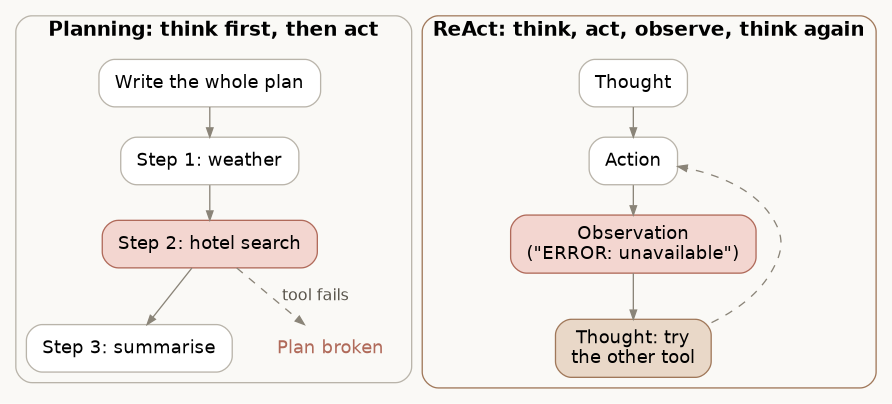

*A fixed plan breaks at the failing step; ReAct observes the error and adapts.*

In [ ]:
# ---- Pretend accommodation tools for this exercise ----
def search_hotels(place: str) -> str:
    """Search hotels in a place.

    Args:
        place: The town or area, for example Old Manali.
    """
    return "ERROR: hotel search service unavailable (HTTP 503). Try again later."

def search_homestays(place: str) -> str:
    """Search homestays and guesthouses in a place.

    Args:
        place: The town or area, for example Old Manali.
    """
    return (f"Homestays in {place} (pretend data): Apple Orchard Homestay, Rs 2,200/night, quiet, veg meals; "
            "Riverside Guesthouse, Rs 1,800/night, near the river.")

accommodation_tools = {"get_weather_forecast": get_weather_forecast, "search_hotels": search_hotels, "search_homestays": search_homestays}
tool_names = list(accommodation_tools.keys())

task = "Find somewhere quiet to stay in Old Manali this week and tell us what weather to expect."

fixed_plan_schema = {"title": "fixed_plan", "description": "A complete plan of tool calls", "type": "object",
                     "properties": {"steps": {"type": "array", "items": {"type": "object", "properties": {
                         "tool": {"type": "string", "enum": tool_names}, "input": {"type": "string"}},
                         "required": ["tool", "input"]}}},
                     "required": ["steps"]}
fixed_plan = llm.with_structured_output(fixed_plan_schema).invoke(
    f"Task: {task}\nTools: get_weather_forecast(place), search_hotels(place), search_homestays(place).\n"
    "Write the complete list of tool calls needed, in order. The plan will be executed exactly as written.")

planning_log = f"TASK: {task}\nPLAN: {fixed_plan['steps']}\n"
plan_broke = False
for number in range(len(fixed_plan["steps"])):
    step = fixed_plan["steps"][number]
    result = accommodation_tools[step["tool"]](step["input"])
    planning_log = planning_log + f"STEP {number + 1}: {step['tool']}({step['input']}) -> {result[:150]}\n"
    print(f"Step {number + 1}: {step['tool']}({step['input']}) -> {result[:90]}")
    # TODO: HW3 [Medium] - Instead of abandoning the plan, ask Gemini for a new plan from the current state (pass the log so far),
    # at most twice. Is it then as robust as ReAct, and how many calls does it use by comparison?
    if result.startswith("ERROR"):
        plan_broke = True
        planning_log = planning_log + "PLAN ABANDONED: a step failed.\n"
        print("Plan broken: this step failed, so every later step that depended on it is invalid.")
        break
print("\nPlanning pattern finished the task:", not plan_broke)

The planner most likely chose `search_hotels`, the obvious tool for "somewhere to stay". When it failed, the strict plan had no way to adapt: classical planning would now need a full, expensive replanning cycle. (If your plan happened to use homestays, the failure did not trigger; re-run the cell, or notice that the plan only survived by luck.)

Now ReAct, with the same tools:

In [ ]:
react_agent = create_agent(model=llm, tools=[get_weather_forecast, search_hotels, search_homestays],
                           system_prompt="You are DilSeTrips. Use the tools step by step. If a tool fails, try another way.")
result = react_agent.invoke({"messages": [HumanMessage(content=task)]})

for message in result["messages"]:
    if type(message).__name__ == "AIMessage" and len(message.tool_calls) > 0:
        for tool_call in message.tool_calls:
            print(f"Action: {tool_call['name']}({tool_call['args']})")
    if type(message).__name__ == "ToolMessage":
        print(f"   Observation: {message.text[:90]}")
print("\nReAct answer:\n" + result["messages"][-1].text)

ReAct hits the same error, observes it, and tries the homestay search: the plan was built one step at a time, so a failure only changes the next step. That robustness is why ReAct is the default for general-purpose LLM agents.

| | Planning (classical) | ReAct (adaptive) |
|---|---|---|
| Core idea | Think first, then act | Think, act, think again |
| Execution | A fixed, pre-computed sequence; one failed step invalidates it | A dynamic loop; the plan grows one step at a time |
| Adaptability | Brittle; replanning is slow and expensive | Robust to surprises and tool failures |
| Efficiency | Expensive up front ("analysis paralysis") | Makes progress with every step |
| Implementation | Classical algorithms (A* search, STRIPS) on a symbolic model | An LLM with a ReAct prompt or native tool calls |
| Output | A formal, verified plan | A log of thoughts, actions and observations |

**Use Planning when** the environment is static and predictable (a factory robot arm with fixed part positions), when optimality really matters (fuel-efficient routes for a truck fleet, where a poor plan is costly) and when the problem is closed and fully defined (solving a Rubik's cube). **Use ReAct when** the environment is dynamic and uncertain (a support bot checking a live order database), when the problem is open-ended or needs outside information (researching the latest in fusion energy) and when robustness beats guaranteed optimality (a discovery agent revising its hypothesis after each experiment).

### 3.4 ReAct agents versus reactive agents

The names are confusingly similar; the designs are opposites.

A **reactive agent** (2.2) runs a **stimulus-response** loop: perceive, then immediately do the predefined thing. No memory, no world model, no planning, like a thermostat. Fast, efficient and lightweight, ideal for quick reflexes in predictable situations; but inflexible, unable to handle new problems or learn.

A **ReAct agent** is an LLM-based agent running a **Thought → Action → Observation** loop. It reasons about its next step, acts with a tool, observes the result and adapts. Thoughtful and adaptable, at the cost of time and model calls.

| Feature | Reactive agent | ReAct agent |
|---|---|---|
| Core principle | Reflexive: sense → act | Iterative: thought → action → observation |
| Reasoning | None | High, through the LLM |
| Memory | None (stateless) | Short-term (the thought history), optionally long-term |
| Environment | Static, predictable | Dynamic, open-ended |
| Flexibility | Rigid | Highly adaptable |
| Example | An obstacle-avoiding robot; a thermostat; DilSeTrips' emergency layer | A research agent; a support chatbot; DilSeTrips' planning layer |

You have now built both, and seen that DilSeTrips needs both: a reactive layer for emergencies, and a ReAct layer for everything that needs thought.

### 3.5 Tool use

Planning and ReAct are reasoning frameworks, brains in a jar. **Tool use** gives those brains hands and eyes. LLMs are trained on a static dataset: they do not know the time, cannot browse, and are unreliable at exact arithmetic. Tools bridge the gap with **live data and specialised abilities**.

A tool is a piece of code, a function or an API the agent can call for a specific external task: a **deterministic, specialised module** that a non-deterministic LLM can rely on, with a clear natural-language description and defined inputs and outputs. Tools come in three kinds:

- **Information retrieval** tools fetch live data: web search, a SQL query, a stock price.
- **Action execution** tools change the world: send an email, book a calendar slot, post a message.
- **Computational or logic** tools give exact results: a code interpreter, a calculator, a format validator.

Every tool use, in any architecture, involves three mechanisms. **Tool selection**, the hardest: the LLM decides which tool fits, guided by the tool descriptions and sometimes by few-shot examples in the prompt. **Parameter generation**: the LLM extracts the right arguments from the request and formats them exactly; mistakes here are **parameter hallucination** (a malformed query, an invented ID). **Output interpretation**: the tool's result, often messy (a long block of search text), must be read, summarised, or recognised as an error.

The flow is always: the system **makes tools available** (name, description, parameters, for example `get_weather(city: string, unit: 'celsius' | 'fahrenheit')`); the model **selects** one when it notices a knowledge gap; it **calls** it; the environment executes it and returns an **observation**. Tool use is the "Action" in ReAct and the "execution" of each step in a Planning framework. In Planning, tool calls are a *consequence* of the plan, top-down and fixed (geocode Paris, then fetch the weather for those coordinates); in ReAct they are *part of* the reasoning, chosen dynamically from the last observation (one broad search for "weather in Paris", then answer). You saw both in 3.3.

Here are all three mechanisms on two requests. DilSeTrips has one tool of each kind; the reminder and currency tools use **pretend data**.

In [ ]:
def add_reminder(text: str, when: str) -> str:
    """Add a reminder to the couple's DilSeTrips app (an action tool).

    Args:
        text: What to remind them about.
        when: When to remind them, for example '2026-12-19 18:00'.
    """
    return f"Reminder set (pretend): '{text}' at {when}."

# TODO: HW4 [Easy] - "How much is 5,000 rupees?" names no target currency, yet the model usually invents one. Rewrite this
# docstring so the model asks instead of guessing. Can a description alone change the behaviour?
def convert_currency(amount: float, from_currency: str, to_currency: str) -> str:
    """Convert an amount between currencies using today's rates (a computational tool).

    Args:
        amount: The amount to convert.
        from_currency: Three-letter code, for example INR.
        to_currency: Three-letter code, for example USD.
    """
    pretend_rates_to_inr = {"INR": 1.0, "USD": 84.0, "EUR": 91.0, "GBP": 107.0}
    if from_currency not in pretend_rates_to_inr or to_currency not in pretend_rates_to_inr:
        return f"ERROR: unknown currency. Known: {list(pretend_rates_to_inr.keys())}"
    result = amount * pretend_rates_to_inr[from_currency] / pretend_rates_to_inr[to_currency]
    return f"{amount} {from_currency} = {result:.2f} {to_currency} (pretend rates)"

tool_user = llm.bind_tools([get_weather_forecast, add_reminder, convert_currency])

requests_to_test = [
    "What's the weather this week in the city where the Taj Mahal is?",
    "How much is 5,000 rupees?",
]
for request in requests_to_test:
    reply = tool_user.invoke(request)
    print(f"Request: {request}")
    for tool_call in reply.tool_calls:
        print(f"   selected: {tool_call['name']}   parameters: {tool_call['args']}")
    if len(reply.tool_calls) == 0:
        print("   no tool selected; reply:", reply.text[:150])
    print()

**Selection** worked on both: weather for the first, currency for the second. **Parameter generation** shows two different things. For the Taj Mahal, the model had to *infer* "Agra" from world knowledge, and that inference was correct and useful. For "how much is 5,000 rupees?", nothing says which currency to convert *to*, so the model usually invents one, typically USD. That is **parameter hallucination**: a plausible argument the user never gave. A better agent asks, or a better tool description says "ask the user if the target currency is unclear" (homework 4).

Now **output interpretation**. The forecast tool returns a dense line of numbers; turning it into an answer is the model's job.

In [ ]:
raw_observation = get_weather_forecast("Agra")
print("What the tool returned (first 300 characters):\n", raw_observation[:300], "\n")
interpreted = llm.invoke(f"Tool result: {raw_observation}\n\nIn two sentences, tell a couple visiting the Taj Mahal "
                         "this week what weather to expect and whether to plan for sun or rain.")
print("Interpreted:\n", interpreted.text)

Interpretation looks easy here, but it is where tool errors slip through: a model can misread a number, overlook an `ERROR:` line, or present "next 7 days" as if it were the trip dates (Session 2's homework). That is one reason the next pattern exists.

### 3.6 Reflection

**Reflection** is a metacognitive pattern: the model critically evaluates its own output to find flaws, refine its reasoning and improve the result, like an author who writes a draft and then puts on an editor's hat. First attempts are often imperfect; an explicit reflection step catches errors, missed requirements, or a better solution.

It is a structured feedback loop, distinct from ReAct's loop because it usually runs *after* an attempt (or a failure). **The input** is the agent's history: the full log of thoughts, actions, observations and errors, not just the final answer. **The engine** is a second LLM call with a **critic prompt** that asks targeted questions: what was the goal? what was the main reason for failure? was there a hallucination, a bad tool call or a logic error? what are two concrete lessons for next time? **The output** is structured self-knowledge: a **critique** (what went wrong), **reasoning** (why), and **lessons learned** (general, actionable, storable).

It runs as a four-step cycle:

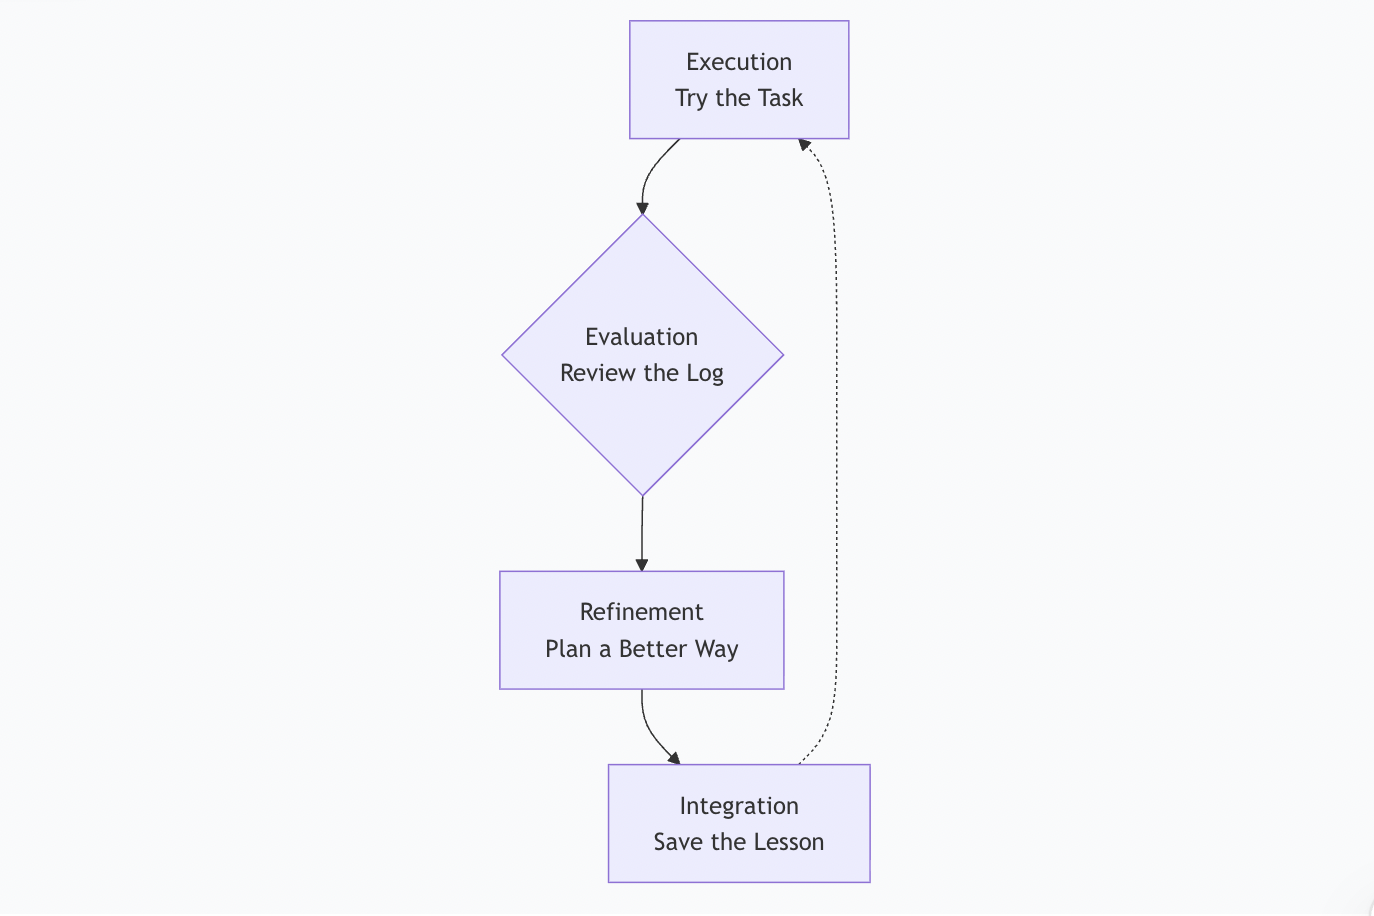

*Execute, evaluate, refine, integrate, and back to execution, on the same task or a new one.*

1. **Execution ("just do it"):** attempt the task, keeping a detailed log, like a pilot's flight journal.
2. **Evaluation ("the review session"):** a critic, often a separate AI acting as a teacher, reads the whole log: was the goal achieved? were there wasted steps? where did it go wrong, logic or tool? what was the single biggest mistake?
3. **Refinement ("the study plan"):** using the critique, write lessons learned or a revised plan, like a student reading a marked exam and planning the retake.
4. **Integration ("save to memory"):** store the lessons in long-term memory, so they can be recalled for similar tasks. Then return to execution, on the same task immediately, or on a new one starting from a better position.

Reflection is less a standalone pattern than a **booster** inside architectures. In **BDI**, it is the re-evaluation phase when an intention fails. In a **layered** system, it belongs to the top deliberative layer, which reviews lower-layer logs to fix persistent problems. In **CoALA and LLM agents** it shines: techniques such as **Reflexion** and **Self-RAG** build a reflective loop in, so a retrieval agent can judge its documents irrelevant and write a better search query. (Session 5's corrective RAG was a reflective step of exactly this kind.)

First, the session document's own example: explain gravity to a five-year-old.

In [ ]:
critique_schema = {
    "title": "critique", "description": "A structured self-review", "type": "object",
    "properties": {
        "meets_requirement": {"type": "boolean"},
        "critique": {"type": "string", "description": "What is wrong, in one or two sentences"},
        "reasoning": {"type": "string", "description": "Why it went wrong"},
        "lessons": {"type": "array", "items": {"type": "string"}, "description": "Short lessons for next time"},
    },
    "required": ["meets_requirement", "critique", "reasoning", "lessons"],
}
critic_llm = llm.with_structured_output(critique_schema)

task_for_child = "Explain gravity to a five-year-old."

# 1. Execution: a deliberately technical first attempt
first_attempt = llm.invoke(task_for_child + " Answer like a physics textbook, in two sentences.").text
print("FIRST ATTEMPT:\n", first_attempt, "\n")

# 2. Evaluation: the critic
review = critic_llm.invoke(f"Task: {task_for_child}\nAnswer: {first_attempt}\n"
                           "Review the answer strictly. Is it appropriate for the audience?")
print("CRITIQUE:", review["critique"])
print("WHY:", review["reasoning"])
print("LESSONS:", review["lessons"], "\n")

# 3. Refinement: try again with the critique
if not review["meets_requirement"]:
    refined = llm.invoke(f"Task: {task_for_child}\nYour previous answer: {first_attempt}\n"
                         f"An editor said: {review['critique']}\nLessons: {review['lessons']}\nWrite a better answer.").text
    print("REFINED:\n", refined)

We forced a textbook-style first attempt ("a fundamental interaction... curvature of spacetime") to make the point clear. The critic flags the jargon as wrong for the audience, and the refinement typically reaches for an image such as a trampoline with a bowling ball making a dip that marbles roll into. Same model, better answer, because of one review step.

Now reflection where it matters most: on an agent's **log**. The Planning run in 3.3 failed. We give its log to the critic, store the lessons, and plan again with them. That is the full four-step cycle, including integration.

In [ ]:
# 2. Evaluation of the failed run's log
log_review = critic_llm.invoke("You are reviewing an agent's execution log.\n" + planning_log +
                               "\nWhat was the goal? What was the primary reason for failure? "
                               "Give two concrete lessons for planning similar tasks in future.")
print("CRITIQUE:", log_review["critique"])
print("LESSONS:", log_review["lessons"], "\n")

# 4. Integration: keep the lessons (a list here; Session 3's vector memory in a real system)
# TODO: HW7 [Hard] - Store these lessons in a vector store and give the planner a different task with a different failing tool.
# Do lessons about hotels help with restaurants? How general should a stored lesson be?
lessons_memory = []
for lesson in log_review["lessons"]:
    lessons_memory.append(lesson)

# 1. Execution again, starting from the lessons
lessons_text = ""
for lesson in lessons_memory:
    lessons_text = lessons_text + "- " + lesson + "\n"
second_plan = llm.with_structured_output(fixed_plan_schema).invoke(
    f"Task: {task}\nTools: get_weather_forecast(place), search_hotels(place), search_homestays(place).\n"
    f"Lessons from a previous failed attempt:\n{lessons_text}"
    "Write the complete list of tool calls needed, in order.")
print("NEW PLAN:")
for step in second_plan["steps"]:
    print(f"   {step['tool']}({step['input']})")

The lessons usually say something like "have a fallback for each critical tool" or "prefer the accommodation tool that is known to work", and the new plan includes `search_homestays`. The planner did not become adaptive like ReAct; it became *wiser* about this kind of task, which is what reflection plus memory gives you.

Reflection's costs: every critique is an extra model call, and there is a risk of over-analysis (reflecting forever instead of finishing). And a critic is another LLM: it can be wrong, and if it is the same model as the producer, it can share the producer's blind spots.

### 3.7 The four patterns compared

| Pattern | Core idea | Strengths | Weaknesses | Use it when |
|---|---|---|---|---|
| Planning | A step-by-step plan before acting, like a recipe before cooking | Structured, predictable; efficient for known tasks; fewer logical errors | Rigid; brittle when things change | Static, predictable environments; when optimality matters (logistics, factories) |
| ReAct | Thought → action → observation in a loop | Adaptable; transparent audit trail; handles dynamic environments | More latency and cost; prompt-sensitive; a bad step can derail it | Open-ended, multi-step problems in uncertain environments |
| Tool use | Extend the LLM with APIs, functions and databases | Fills LLM gaps (maths, live data, actions) | Wrong tool or wrong parameters cause errors | Tasks that need outside information or actions |
| Reflection | Critique your own output or log, then improve | Better quality; learns from mistakes; iterative improvement | Extra calls; risk of over-analysis | When accuracy and reliability matter |

By combining these four (Planning or ReAct for reasoning, Tools for acting, Reflection for quality), you can build agents that are not just knowledgeable but capable, adaptive and reliable.

## 4. Hands-on: one agent, several patterns

The session plan asks for a hands-on agent that integrates several design patterns, and provides reference code for it. Read it critically first; it contains a bug worth finding.

The reference agent runs a planning call, a single "ReAct" call that writes `Thought:` and `Action:` text, a tool step, a final answer, and a reflection call. Its tool step is:

```python
if "get_weather" in react_result.lower():
    # Simple demo extraction
    city = "Gurgaon"
    observation = get_weather.invoke({"city": city})
```

Whatever city the user asked about, and whatever city the model wrote in its Action line, **this always fetches Gurgaon's weather**. Here is that exact decision branch, run on a ReAct output asking about Mumbai (no LLM call needed to see it):

In [ ]:
def reference_get_weather(city):
    """The reference code's dummy weather tool."""
    weather_data = {"gurgaon": "32°C, Sunny", "delhi": "33°C, Partly Cloudy", "mumbai": "29°C, Rainy"}
    return weather_data.get(city.lower(), f"Weather data not available for {city}")

# What the model's ReAct step might return for "What is the weather in Mumbai today?"
react_result = "Thought: The user wants Mumbai's weather. I should use the weather tool.\nAction: get_weather(Mumbai)"

# The reference code's tool-use branch, unchanged
if "get_weather" in react_result.lower():
    city = "Gurgaon"
    observation = reference_get_weather(city)

print("The model asked for:  Mumbai")
print("The code fetched for:", city)
print("Observation:         ", observation, " <- Gurgaon's weather, presented as the answer about Mumbai")

The final answer would confidently report Mumbai as "32°C, Sunny", which is Gurgaon's data, and the reflection step cannot catch it, because nothing tells the critic which city the data belongs to. Three more points about the reference code:

- **It is not a reactive agent**, although its heading says so. It plans, reasons and reflects; it has no stimulus-response layer.
- **Its "ReAct" runs once**: one Thought and one Action, with no observation fed back for another thought. The loop that defines ReAct is missing.
- **It passes `temperature=0`** to a Gemini 3 model, which ignores it and prints a warning, and the tool's data is hard-coded.

Here is a corrected version of the same idea, built from what you wrote in this session. It integrates **five** things: a **reactive** layer first (the hot-stove reflex, so it really is a reactive agent at its base); **planning** (a short structured plan); **ReAct with tool use** (`create_agent` with the real weather tool, which loops until done, so the city always comes from the model's own tool call); and **reflection** (a structured check of the answer *against the tool observations*, so wrong-city or misread data can be caught).

In [ ]:
short_plan_schema = {"title": "short_plan", "description": "A short plan", "type": "object",
                     "properties": {"steps": {"type": "array", "items": {"type": "string"}}}, "required": ["steps"]}
answer_check_schema = {"title": "answer_check", "description": "A check of an answer against tool evidence", "type": "object",
                       "properties": {"supported": {"type": "boolean", "description": "Is every claim backed by the tool observations?"},
                                      "problems": {"type": "string"},
                                      "improved_answer": {"type": "string", "description": "A corrected answer, or the same answer if fine"}},
                       "required": ["supported", "problems", "improved_answer"]}

def dilsetrips_agent(user_message):
    print(f"USER: {user_message}")

    # 1. Reactive pattern: reflexes first, no LLM
    reflex = reactive_layer(user_message)
    if reflex is not None:
        print("--- REACTIVE --- answered instantly")
        return reflex

    # 2. Planning pattern
    plan = llm.with_structured_output(short_plan_schema).invoke(
        "Write a plan of at most 3 short steps to answer this request:\n" + user_message)["steps"]
    print("--- PLAN ---")
    for step in plan:
        print("   -", step)

    # 3 + 4. ReAct with tool use: the agent loops, and chooses the tool's arguments itself
    plan_text = "\n".join(plan)
    executor = create_agent(model=llm, tools=[get_weather_forecast],
                            system_prompt="You are DilSeTrips. Follow this plan, using tools as needed:\n" + plan_text)
    result = executor.invoke({"messages": [HumanMessage(content=user_message)]})
    observations = ""
    print("--- REACT + TOOL USE ---")
    for message in result["messages"]:
        if type(message).__name__ == "AIMessage" and len(message.tool_calls) > 0:
            for tool_call in message.tool_calls:
                print(f"   Action: {tool_call['name']}({tool_call['args']})")
        if type(message).__name__ == "ToolMessage":
            observations = observations + message.text + "\n"
    draft_answer = result["messages"][-1].text

    # 5. Reflection pattern: check the answer against the evidence
    # TODO: HW5 [Medium] - The reviewer sees the tool observations but not the user's original constraints from memory
    # (Session 3). What else should it check, and when should it refuse to answer rather than "improve"?
    check = llm.with_structured_output(answer_check_schema).invoke(
        f"Request: {user_message}\nTool observations:\n{observations}\nDraft answer: {draft_answer}\n"
        "Check every claim in the draft against the observations (right place? right dates? right numbers?).")
    problems = check["problems"]
    if problems == "":
        problems = "none"
    print(f"--- REFLECTION --- supported: {check['supported']}  problems: {problems}")
    if check["supported"]:
        return draft_answer
    return check["improved_answer"]

print("\nFINAL:", dilsetrips_agent("What's the weather in Mumbai this week, and should we carry umbrellas?"))

In [ ]:
print("FINAL:", dilsetrips_agent(saturday_message))

The weather question goes through plan, ReAct with the real tool (Mumbai, chosen by the model), and a reflection check against the observations. Saturday night's message never reaches an LLM: the reactive layer answers in under a millisecond. Same agent, two very different amounts of thinking, chosen per message. That is the whole session in two cells.

## 5. Conclusions

**There is no single best architecture.** Deliberative (slow, careful planning), reactive (fast, direct response) or hybrid: the choice depends on the task. DilSeTrips needed a reflex for emergencies and a planner for itineraries in the same product.

**Hybrid architectures are where real systems end up.** BDI balances commitment with reaction; layered architectures combine reflex, routine and strategy; CoALA organises an LLM-centred agent around memory, actions and decisions.

**LLMs act as a dynamic engine.** They replaced rigid rules and plan libraries with flexible reasoning, planning and self-correction, at the cost of latency, money and unpredictability. That cost is why the reactive layer still matters.

**Design patterns give agents their specific abilities.** Planning and ReAct structure reasoning; Tool Use connects it to the world; Reflection improves its quality. You combined all of them, plus a reactive layer, in one agent.

### What you built, and what is still yours to decide

| Idea | Your code | The decision it leaves you |
|---|---|---|
| Deliberative | LLM plan checked against preconditions (2.1) | Which rules must code enforce, rather than trusting the model? |
| Reactive | Keyword safety layer, under 1 ms (2.2) | Missed emergencies versus false alarms (homework 1) |
| BDI | Beliefs, desires, intention; small versus big events (2.3) | How big must an event be to drop a commitment? |
| Layered | Orchestrator routing to reflex, routine or planning (2.4) | Which messages deserve how much thinking? |
| CoALA | Propose, evaluate, select (2.5) | The weights in the selection (we chose safety first) |
| Planning versus ReAct | The same failing tool, two outcomes (3.3) | Optimality or adaptability? |
| Tool use | Selection, parameters, interpretation (3.5) | Ask the user, or let the model guess parameters? |
| Reflection | Gravity, and lessons from a failed log (3.6) | When to stop reflecting, and who reviews the reviewer? |

No architecture or pattern makes an agent's answers true. Reflection catches some errors, but the critic is another model; only tool results can be traced to a source, and the reference code showed how even a tool result can quietly be the wrong one.

## 6. Homework

Items marked in the code have a `# TODO: HWn` comment at the exact line.

| # | Level | Task | Where |
|---|---|---|---|
| HW1 | Easy | Missed emergencies versus false alarms | `reactive_layer`, 2.2 |
| HW2 | Medium | An LLM safety check in the router | 2.4 |
| HW3 | Medium | Replanning inside the Planning pattern | 3.3 |
| HW4 | Easy | Stop parameter hallucination | `convert_currency`, 3.5 |
| HW5 | Medium | A stricter reviewer | `dilsetrips_agent`, Chapter 4 |
| HW6 | Hard | BDI with memory | 2.3 |
| HW7 | Hard | Reflection with long-term lessons | 3.6 |

**HW2 [Medium]: a safety check in the router.** "Our car died near Rohtang" slips past the keyword layer. Add a field `is_emergency` (boolean) to `router_schema` and send emergencies to the reactive reply. What does this cost in latency for *every* message, and is it worth it? Could you run it only when the keyword layer finds nothing?

**HW3 [Medium]: replanning.** Change the Planning execution in 3.3 so that when a step fails, it asks Gemini for a new plan from the current state (passing the log so far), at most twice. Is it now as robust as ReAct? How many calls does it use compared with the ReAct agent?

**HW4 [Easy]: parameter hallucination.** Rewrite the `convert_currency` docstring so the model asks which currency to convert to instead of guessing. Re-run "How much is 5,000 rupees?". Did the description alone change the behaviour?

**HW6 [Hard]: BDI with memory.** Store the BDI beliefs from 2.3 in a vector memory like Session 3's, split into semantic beliefs (facts) and episodic beliefs (experiences). When an event arrives, retrieve the relevant beliefs instead of passing them all. What changes when the agent has a hundred beliefs instead of six?

**HW7 [Hard]: long-term lessons.** Save the lessons from 3.6 in a vector store, then give the Planning agent a *different* task with a failing tool (for example, a restaurant search that is down). Retrieve lessons by similarity. Do lessons about hotels help with restaurants? What does that tell you about how general a lesson should be?

**Suggested order.** HW1 and HW4 first (no new structure). Then HW2, which builds on HW1. Then HW3 and HW5, about making plans and answers more robust. HW6 and HW7 connect this session to Session 3's memory; do them last.

## 7. Quick reference

| Idea | One line | Code |
|---|---|---|
| The question | How much thinking does this moment need? | the thinking dial |
| Deliberative | Sense → think → act; plans ahead | `action_rules`, plan validation |
| Reactive | Sense → act; reflexes, no model | `reactive_layer` |
| Subsumption | Higher layers override lower ones | safety before instant answers before the LLM |
| BDI | Beliefs, desires, committed intentions | `bdi_schema`, `reconsider_schema` |
| Layered | Reflex, routine and strategy layers with an orchestrator | `orchestrator` |
| CoALA | Memory, actions (internal and external), decisions | propose, evaluate, select |
| Planning pattern | Whole plan first, then execute | `fixed_plan_schema` |
| ReAct pattern | Thought → action → observation | hand-written loop; `create_agent` |
| Tool use | Selection, parameters, interpretation | `bind_tools`, `tool_calls` |
| Reflection | Critique, lessons, retry | `critique_schema`, `lessons_memory` |